# IDX Exchange DS Internship - Week Five -  Additional Models

* Try Decision Tree and Random Forest regressors.
* Compare their test R² against baseline.
* Document model behavior (strengths/weaknesses)

-------

In [1]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error

import matplotlib.pyplot as plt

This notebook will test decision trees and random forest models for predicting ClosePrice. The first few models in each section use the dataset created in week three, while the remaining models use the feature engineered dataset created in week six. Various iterations will be made to each model to see how performance changes. Additionally, the models will be tuned on the validation set and evaluated using $R^2$, MAPE, MdAPE, and MAE metrics. 

## Import Data

In [28]:
# Read in the training and test sets created in week three

train_and_val = pd.read_csv("week_3_train_2.csv")
testing = pd.read_csv("week_3_test_2.csv")

In [29]:
# Create a validation set out of the training data

# Training Set: January 2024 - February 2026
# Validation Set: March 2026
# Test Set: April 2026

training = train_and_val[~(train_and_val["PropertyMonth"] == "2026-03-01")]
validation = train_and_val[train_and_val["PropertyMonth"] == "2026-03-01"]

print(train_and_val.shape, training.shape, validation.shape)

(265326, 47) (255033, 47) (10293, 47)


In [2]:
def median_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.median(np.abs((y_true - y_pred) / y_true))

def metrics(y_true, y_pred):
    # Note: you have to undeo the log transform on ClosePrice by using np.exp()!
    y_true = np.exp(y_true)
    y_pred = np.exp(y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    mdape = median_absolute_percentage_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    return r2, mape * 100, mdape * 100, mae

def metrics_no_log(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    mdape = median_absolute_percentage_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    return r2, mape * 100, mdape * 100, mae

def metric_df(r2_train, mape_train, mdape_train, mae_train,
              r2_val, mape_val, mdape_val, mae_val,
              r2_test, mape_test, mdape_test, mae_test):
    data = {"r2": [r2_train, r2_val, r2_test],
            "MAPE": [mape_train, mape_val, mape_test],
            "MdAPE": [mdape_train, mdape_val, mdape_test],
            "MAE": [f"${round(mae_train, 2)}", f"${round(mae_val, 2)}", f"${round(mae_test, 2)}"]}
    df = pd.DataFrame(data)
    df.index = ["Train Set", "Validation Set", "Test Set"]
    return df

In [31]:
# Columns not being used: "ListingKey", "ListingId", "ClosePrice", "ListOfficeName", "CountyOrParish", "YearBuilt",
#         "City", "HighSchoolDistrict", "PostalCode", "LivingArea", "LotSizeSquareFeet", "AssociationFee"

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog",
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "PropertyMonth", "ClosePriceLog"]

# The x_train window will be set per model, so don't define it here

x_val = validation[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc"]]  
y_val = validation["ClosePriceLog"]


x_test = testing[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc"]]
y_test = testing["ClosePriceLog"]

## Decision Trees

### Model One: Baseline Decision Tree

Train a decision tree model on the dataset created in week three in order to establish a baseline. To ensure the model is not overfitting to a specific timeframe, train it on three different windows. `max_depth` will be tuned using the validation set, and then applied to the testing set for evaluation.

#### Train Set: January 2024 - February 2026

In [32]:
# Use the full set of available months (26 months)

x_train = training[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_train = training["ClosePriceLog"]

In [33]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

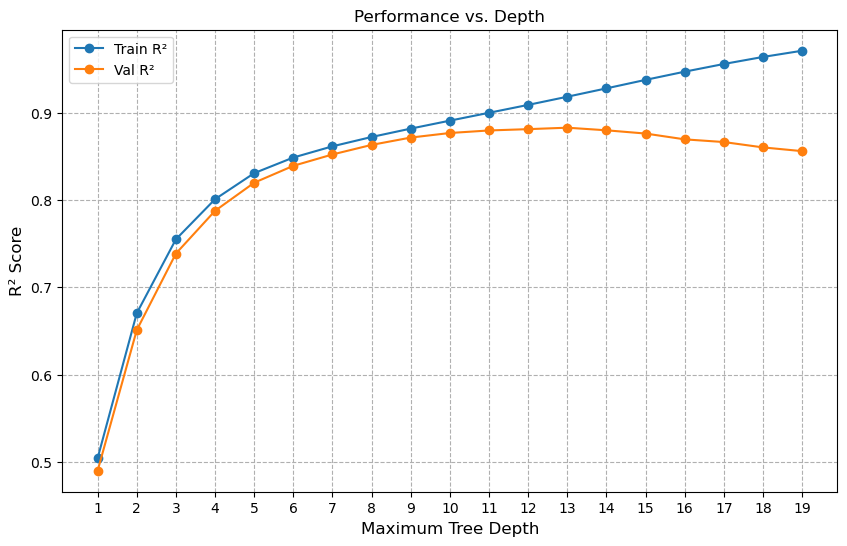

In [34]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [35]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 13


In [36]:
model_one_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_one_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.894675,10.588249,7.741143,$120275.45
Validation Set,0.842665,12.475448,8.860581,$144509.78
Test Set,0.863098,11.968947,8.629764,$143130.74


These are promising results! On the same data, the linear regression model got an r2 score of 0.845539, as well as higher MAPE, MdAPE, and MAE metrics. This shows a clear improvement over the linear regression model when using a decision tree. This indicates that there are non-linear relationships in the data which are predictive of ClosePrice.

#### Train Set: February 2025 - February 2026

Train the same model as above on a different training window to see if the model is overfitting. The training window in this section will be cut down to a year (as opposed to 26 months in the model above).

In [37]:
# Shorten the training window to the year preceding the validation set (12 months)

past_limit = pd.to_datetime("2025-01-01")
present_limit = pd.to_datetime("2026-02-01")

x_train_with_month = training[common_cols]
x_train_with_month.loc[:, "PropertyMonth"] = pd.to_datetime(x_train_with_month["PropertyMonth"])
x_train = x_train_with_month[(x_train_with_month["PropertyMonth"] >= past_limit) & (x_train_with_month["PropertyMonth"] <= present_limit)]
y_train = x_train["ClosePriceLog"]
x_train = x_train.drop(columns = ["PropertyMonth", "ClosePriceLog"])

In [38]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

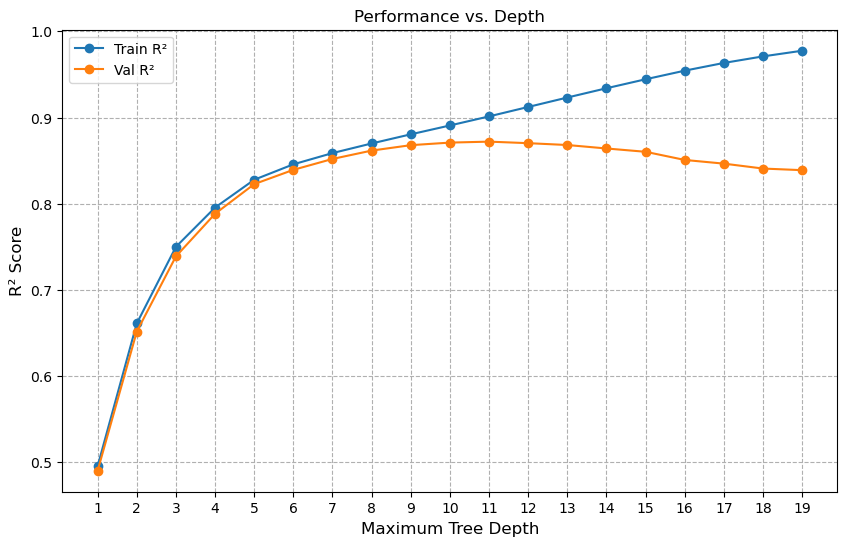

In [39]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [40]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 11


In [41]:
model_one_v2 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_one_v2

,r2,MAPE,MdAPE,MAE
Train Set,0.873885,11.705734,8.714478,$132262.04
Validation Set,0.833467,13.244417,9.527670,$151538.1
Test Set,0.848697,12.635319,9.226166,$150725.68


When 12 months are used for the training data instead of 26, model performance decreases a bit. However, this model still outperforms linear regression on the full dataset. Rather than being overfit, the small drop in performance is likely because the training set has been halved, rather than being indicative of an overfitting problem.

#### Train Set: July 2024 - February 2026

Test this model on one more training window to be sure of the above conclusions.

In [42]:
# Set the training window to 20 months preceding the validation set

past_limit = pd.to_datetime("2024-06-01")
present_limit = pd.to_datetime("2026-02-01")

x_train_with_month = training[common_cols]
x_train_with_month.loc[:, "PropertyMonth"] = pd.to_datetime(x_train_with_month["PropertyMonth"])
x_train = x_train_with_month[(x_train_with_month["PropertyMonth"] >= past_limit) & (x_train_with_month["PropertyMonth"] <= present_limit)]
y_train = x_train["ClosePriceLog"]
x_train = x_train.drop(columns = ["PropertyMonth", "ClosePriceLog"])

In [43]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

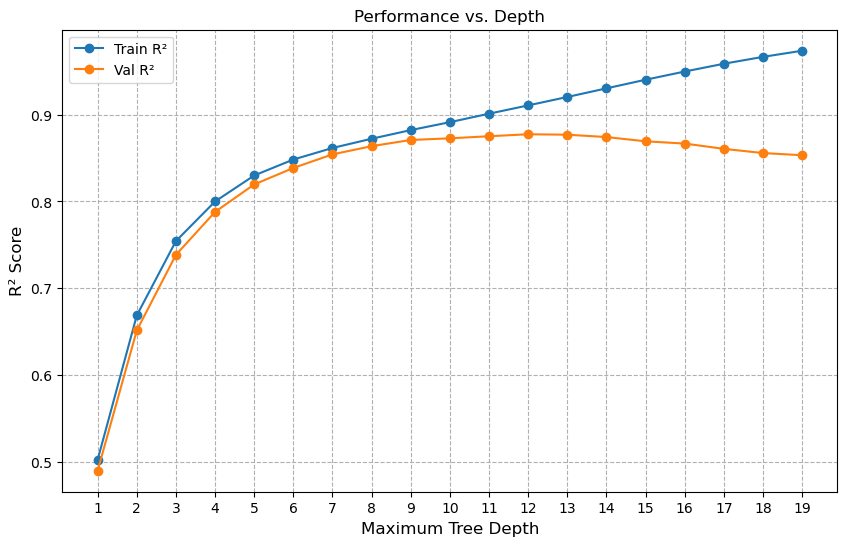

In [44]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [45]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 12


In [46]:
model_one_v3 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_one_v3

,r2,MAPE,MdAPE,MAE
Train Set,0.885216,11.113209,8.191083,$126271.25
Validation Set,0.838579,12.971772,9.344429,$149539.57
Test Set,0.855459,12.402724,8.897190,$146903.45


This reduced training set model still outperforms linear regression on the full dataset. This suggests that this decision tree model is robust to changes in training window and has good predict power.

### Model Two: Outlier Winsorized Decision Tree

During preprocessing, ClosePrice had its largest and smallest values dropped in order to remove outliers. Furthermore, all large numeric values had log transforms performed on them to fix their right-skew. However, outliers were not dropped for these large numeric features. Test if winsorizing the large numeric features improves performance.

In [47]:
# Columns to winsorize: "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog"

winz_tv = train_and_val.copy()
winz_test = testing.copy()

upper_bound = winz_tv["LivingAreaLog"].quantile(0.95)
winz_tv["LivingAreaLog"] = winz_tv["LivingAreaLog"].clip(lower=0, upper=upper_bound)
winz_test["LivingAreaLog"] = winz_test["LivingAreaLog"].clip(lower=0, upper=upper_bound)

upper_bound = winz_tv["AssociationFeeLog"].quantile(0.95)
winz_tv["AssociationFeeLog"] = winz_tv["AssociationFeeLog"].clip(lower=0, upper=upper_bound)
winz_test["AssociationFeeLog"] = winz_test["AssociationFeeLog"].clip(lower=0, upper=upper_bound)

upper_bound = winz_tv["LotSizeSquareFeetLog"].quantile(0.95)
winz_tv["LotSizeSquareFeetLog"] = winz_tv["LotSizeSquareFeetLog"].clip(lower=0, upper=upper_bound)
winz_test["LotSizeSquareFeetLog"] = winz_test["LotSizeSquareFeetLog"].clip(lower=0, upper=upper_bound)

In [48]:
training_winz = winz_tv[~(winz_tv["PropertyMonth"] == "2026-03-01")]
validation_winz = winz_tv[winz_tv["PropertyMonth"] == "2026-03-01"]

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog",
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc"]

x_train = training_winz[common_cols]
y_train = training_winz["ClosePriceLog"]

x_val = validation_winz[common_cols]  
y_val = validation_winz["ClosePriceLog"]

x_test = winz_test[common_cols]
y_test = winz_test["ClosePriceLog"]

In [49]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

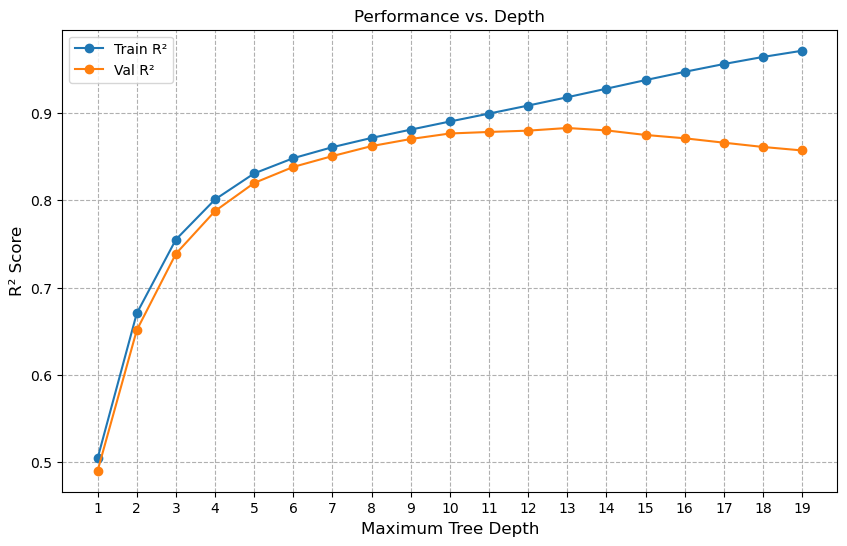

In [50]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [51]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 13


In [52]:
model_two_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_two_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.893126,10.583716,7.715211,$120678.43
Validation Set,0.841958,12.442390,8.857898,$144952.29
Test Set,0.860333,11.989024,8.658441,$143242.2


The performance for the winsorized model is on par with the baseline model, though very slightly under. This suggests that winsorization of large numeric features does not improve model performance, and we are better off not doing it.

### Model Three: BedBathRatio and PropertyAge

Two features, BedBathRatio and PropertyAge, were created during the feature engineering done in week six. Test how model performance changes with the inclusion of these new features.

In [3]:
# Read in the training and test sets created in week six

train_and_val = pd.read_csv("feat_eng_train.csv")
testing = pd.read_csv("feat_eng_test.csv")

In [4]:
training = train_and_val[~(train_and_val["PropertyMonth"] == "2026-03-01")]
validation = train_and_val[train_and_val["PropertyMonth"] == "2026-03-01"]

print(train_and_val.shape, training.shape, validation.shape)

(265296, 153) (255004, 153) (10292, 153)


In [55]:
common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "BedBathRatio", "PropertyAge"]

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]


x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [56]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

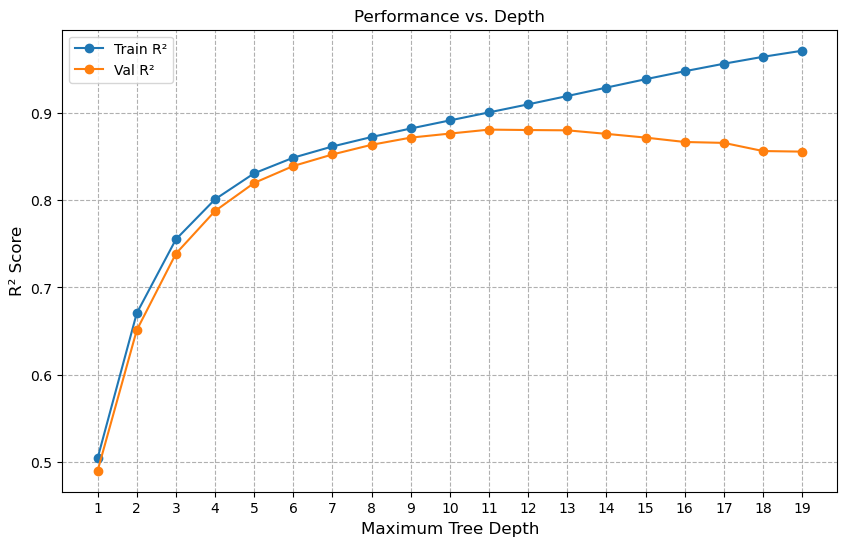

In [57]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [58]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 11


In [59]:
model_three = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_three

,r2,MAPE,MdAPE,MAE
Train Set,0.872205,11.806575,8.763782,$134122.64
Validation Set,0.845413,12.791129,9.414370,$146637.54
Test Set,0.862362,12.277405,9.091912,$145901.96


After the addition of these new features, the model performance actually goes down compared to the baseline! While the metrics remain quite similar, there is still a very small decrease in performance for every metric. This is very interesting, since the perfomance of the linear regression model improved after the inclusion of these features. This likely indicates that there is a linear relationship between BedBathRatio/PropertyAge and ClosePrice, which is better captured by the linear model than a decision tree.

### Model Four: Improved School Districts

During week six, the existing dataset was joined with the California School District Areas 2024-2025 dataset (https://data.ca.gov/@california-department-of-education/california-school-district-areas-2024-25) to improve the locational data. Test how the model performance changes with these new features. Additionally, since BedBathRatio and PropertyAge didn't increase model performance, don't use them as features in this section.

#### Both Counts and Percents

In [186]:
# The new dataset contains school district names, as well as demographic data from that district
# This section will include both the percent and count columns that describe demographic information

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "DistrictName_elem_enc", "DistrictName_unif_enc", "DistrictName_high_enc",
            'EnrollTotal_high', 'EnrollCharter_high', 'EnrollNonCharter_high', 'AApct_high', 'AAcount_high', 'AIpct_high',
            'AIcount_high', 'ASpct_high', 'AScount_high', 'FIpct_high', 'FIcount_high', 'HIpct_high', 'HIcount_high', 'PIpct_high',
            'PIcount_high', 'WHpct_high', 'WHcount_high', 'MRpct_high', 'MRcount_high', 'NRpct_high', 'NRcount_high', 'ELpct_high',
            'ELcount_high', 'FOSpct_high', 'FOScount_high','HOMpct_high','HOMcount_high','MIGpct_high','MIGcount_high','SWDpct_high',
            'SWDcount_high','SEDpct_high','SEDcount_high', 'EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem','AApct_elem',
            'AAcount_elem','AIpct_elem','AIcount_elem','ASpct_elem','AScount_elem','FIpct_elem','FIcount_elem','HIpct_elem','HIcount_elem',
            'PIpct_elem','PIcount_elem','WHpct_elem','WHcount_elem','MRpct_elem','MRcount_elem','NRpct_elem','NRcount_elem','ELpct_elem',
            'ELcount_elem','FOSpct_elem','FOScount_elem','HOMpct_elem','HOMcount_elem','MIGpct_elem','MIGcount_elem','SWDpct_elem',
            'SWDcount_elem','SEDpct_elem','SEDcount_elem','EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif','AApct_unif',
            'AAcount_unif','AIpct_unif','AIcount_unif','ASpct_unif','AScount_unif','FIpct_unif','FIcount_unif','HIpct_unif','HIcount_unif',
            'PIpct_unif','PIcount_unif','WHpct_unif','WHcount_unif','MRpct_unif','MRcount_unif','NRpct_unif','NRcount_unif','ELpct_unif',
            'ELcount_unif','FOSpct_unif','FOScount_unif','HOMpct_unif','HOMcount_unif','MIGpct_unif','MIGcount_unif','SWDpct_unif',
            'SWDcount_unif','SEDpct_unif','SEDcount_unif']

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [187]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

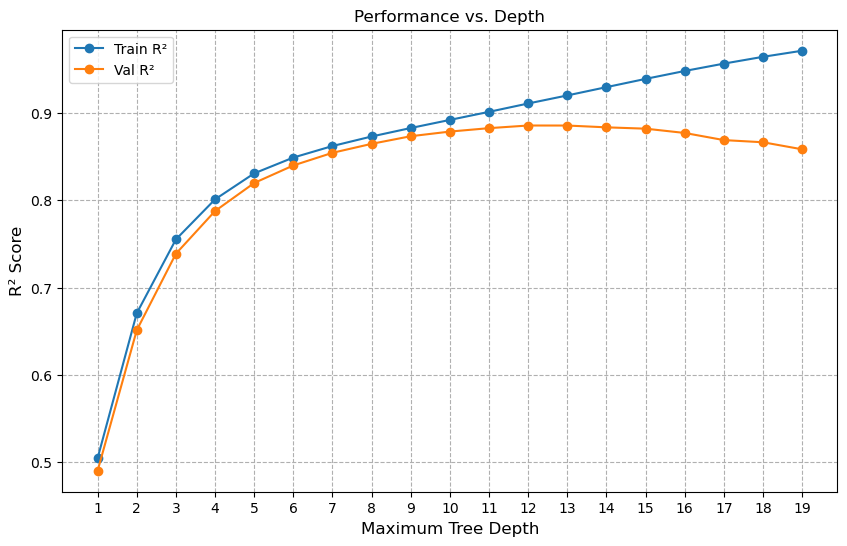

In [188]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [189]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 12


In [190]:
model_four_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_four_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.885306,11.106281,8.173032,$126063.81
Validation Set,0.849413,12.462355,9.067247,$143448.33
Test Set,0.866065,11.967310,8.697241,$142252.42


With the addition of the school district data, there is a small improvement in performance compared to the baseline. This makes sense, since school districts as a feature should capture a non-linear relationship that a decision tree would be adept and learning.

#### Only Percents

In this section, use only percentages to encode demographic data.

In [181]:
# Test if model performance changes when only the percent columns are used for demographic information

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "DistrictName_elem_enc", "DistrictName_unif_enc", "DistrictName_high_enc",
            'EnrollTotal_high', 'EnrollCharter_high', 'EnrollNonCharter_high', 'AApct_high', 'AIpct_high',
            'ASpct_high','FIpct_high','HIpct_high','PIpct_high',
            'WHpct_high','MRpct_high', 'NRpct_high', 'ELpct_high',
            'FOSpct_high', 'HOMpct_high','MIGpct_high','SWDpct_high',
            'SEDpct_high','EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem','AApct_elem',
            'AIpct_elem','ASpct_elem','FIpct_elem','HIpct_elem',
            'PIpct_elem','WHpct_elem','MRpct_elem','NRpct_elem','ELpct_elem',
            'FOSpct_elem','HOMpct_elem','MIGpct_elem','SWDpct_elem',
            'SEDpct_elem','EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif','AApct_unif',
            'AIpct_unif','ASpct_unif','FIpct_unif','HIpct_unif',
            'PIpct_unif','WHpct_unif','MRpct_unif','NRpct_unif','ELpct_unif',
            'FOSpct_unif','HOMpct_unif','MIGpct_unif','SWDpct_unif',
            'SEDpct_unif']

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [182]:
depths = range(1, 20)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(x_train, y_train)

    train_r2 = model.score(x_train, y_train)
    val_r2 = model.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

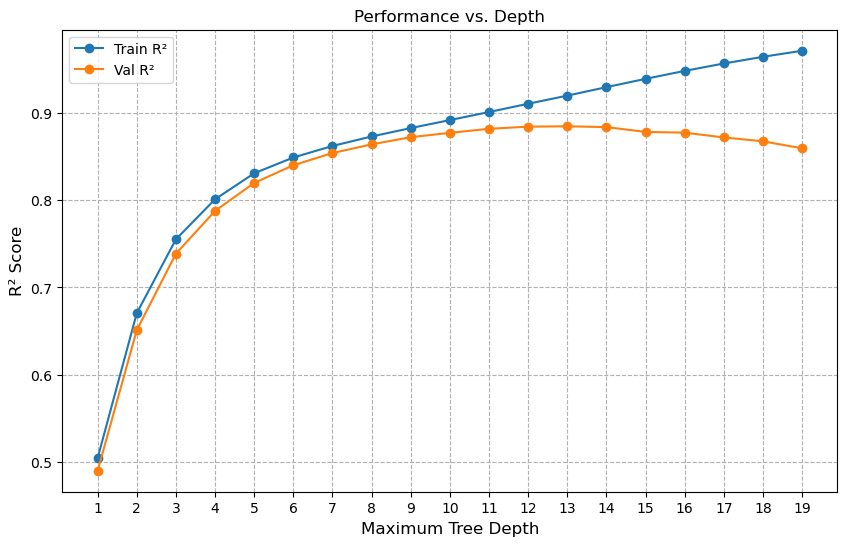

In [183]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [184]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
model.fit(x_train, y_train)

pred_train = model.predict(x_train)
pred_val = model.predict(x_val)
pred_test = model.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 13


In [185]:
model_four_v2 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
model_four_v2

,r2,MAPE,MdAPE,MAE
Train Set,0.896838,10.459999,7.621288,$118653.64
Validation Set,0.848693,12.430279,8.936427,$142862.06
Test Set,0.867673,11.783563,8.438892,$140170.72


Model performance increases slightly when only percentages are used to encode demographic data, rather than both percentages and counts.

### Decision Tree Summary

This table presents the best performing model from each section.

| Model | Test r2 | Test MAPE | Test MdAPE | Test MAE |
| ----- | ------- | --------- | ---------- | -------- |
| Model One (Baseline) | 0.863098 | 11.968947 | 8.629764 | \$143,130 |
| Model Two (Large Numeric Features Winsorized) | 0.860333 | 11.989024 | 8.658441 | \$143,242 | 
| Model Three (Feature Engineering Additions) | 0.862362| 12.277405| 9.091912 | \$143,242 |
| **Model Four (Improved School Districts)** | **0.867673** | **11.783563** | **8.438892** | **\$140,170**|

Overall, every decision tree outperforms the linear regression models on the same data. This indicates that there are non-linear relationships with ClosePrice within our dataset. Going forward, we can expect non-linear models to have better predictive power for this dataset.

## Random Forests

Now that we've tested decision trees, we should also test random forests. Random forests are an aggregated version of many decision trees, and they tend to work best on large, complex datasets. As an ensemble method, we should expect random forests to outperform decision trees.

In [191]:
# Read in the week three datasets again for easy access

train_and_val = pd.read_csv("week_3_train_2.csv")
testing = pd.read_csv("week_3_test_2.csv")

In [192]:
training = train_and_val[~(train_and_val["PropertyMonth"] == "2026-03-01")]
validation = train_and_val[train_and_val["PropertyMonth"] == "2026-03-01"]

In [193]:
# Columns not being used: "ListingKey", "ListingId", "ClosePrice", "ListOfficeName", "CountyOrParish", "YearBuilt",
#         "City", "HighSchoolDistrict", "PostalCode", "LivingArea", "LotSizeSquareFeet", "AssociationFee"

common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog",
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "PropertyMonth", "ClosePriceLog"]

# The x_train window will be set per model, so don't define it here

x_val = validation[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc"]]  
y_val = validation["ClosePriceLog"]


x_test = testing[["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc"]]
y_test = testing["ClosePriceLog"]

### Model One: Baseline Random Forest

Train a random forest model on the dataset created in week three in order to establish a baseline. To ensure the model is not overfitting to a specific timeframe, train it on three different windows. `max_depth` will be tuned using the validation set, and then applied to the testing set for evaluation. `n_estimators` will be kept at the default of 100 to ease computation.

#### Train Set: January 2024 - February 2026

In [194]:
# Use the full set of available months (26 months)

x_train = training[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_train = training["ClosePriceLog"]

In [137]:
depths = range(1, 20, 3)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

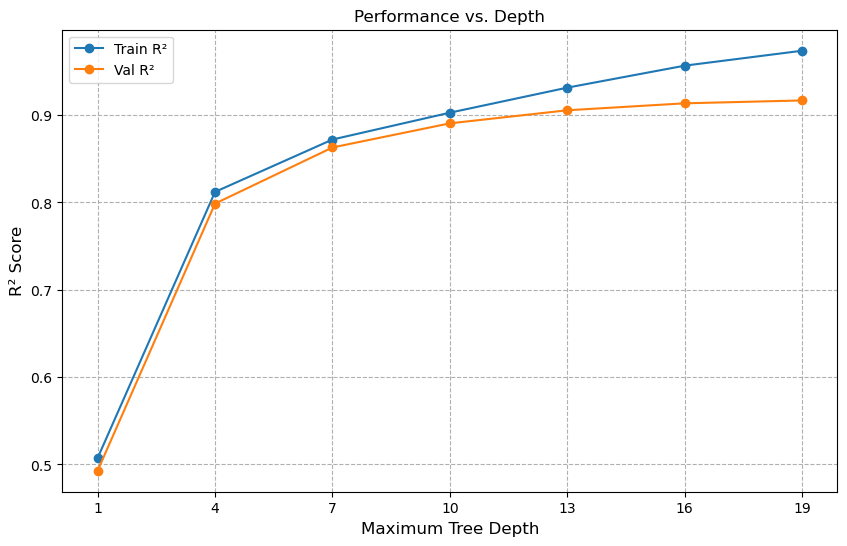

In [138]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [139]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [140]:
rf_one_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_one_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.966687,6.124628,4.647852,$69358.02
Validation Set,0.886422,10.533720,7.483323,$122930.56
Test Set,0.902822,9.853777,6.941994,$118341.45


These results show that using random forests instead of simple decision trees leads to a large boost in model performance. It makes sense that a complex dataset like the one we're using is better predicted by a model that works well with high model-complexity.

#### Train Set: February 2025 - February 2026

We should test a few different training windows to check that our results still remain in the same range. Shrink the training window down to a year for this section.

In [141]:
common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog",
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "PropertyMonth", "ClosePriceLog"]

past_limit = pd.to_datetime("2025-01-01")
present_limit = pd.to_datetime("2026-02-01")

x_train_with_month = training[common_cols]
x_train_with_month.loc[:, "PropertyMonth"] = pd.to_datetime(x_train_with_month["PropertyMonth"])
x_train = x_train_with_month[(x_train_with_month["PropertyMonth"] >= past_limit) & (x_train_with_month["PropertyMonth"] <= present_limit)]
y_train = x_train["ClosePriceLog"]
x_train = x_train.drop(columns = ["PropertyMonth", "ClosePriceLog"])

In [142]:
depths = range(1, 20, 3)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

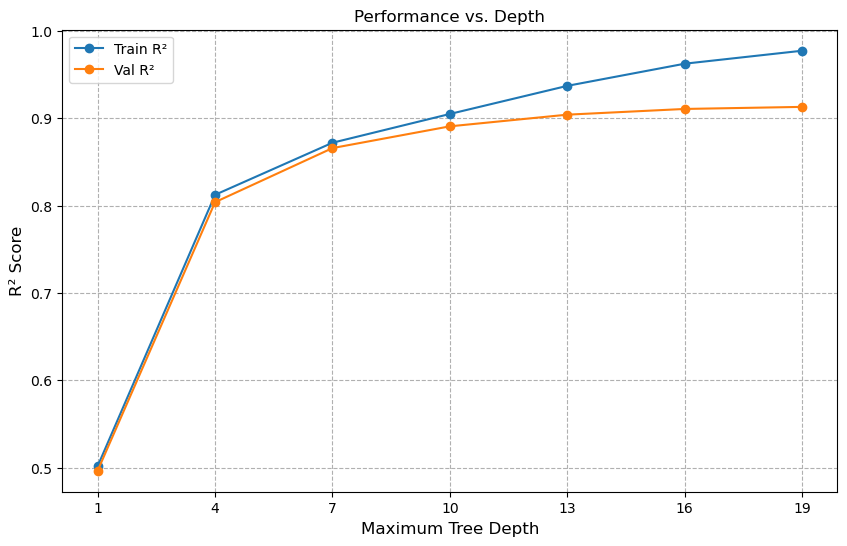

In [143]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [144]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [145]:
rf_one_v2 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_one_v2

,r2,MAPE,MdAPE,MAE
Train Set,0.970563,5.689347,4.344682,$64268.27
Validation Set,0.880494,10.781171,7.653398,$125908.58
Test Set,0.891503,10.479777,7.512526,$126057.68


The performance decreases a little when the training window is halved, but not enough to be indicative of a problem.

#### Train Set: July 2024 - February 2026

Try one more different training window to see how it affects performance.

In [146]:
# Set the training window to 20 months preceding the validation set

past_limit = pd.to_datetime("2024-06-01")
present_limit = pd.to_datetime("2026-02-01")

x_train_with_month = training[common_cols]
x_train_with_month.loc[:, "PropertyMonth"] = pd.to_datetime(x_train_with_month["PropertyMonth"])
x_train = x_train_with_month[(x_train_with_month["PropertyMonth"] >= past_limit) & (x_train_with_month["PropertyMonth"] <= present_limit)]
y_train = x_train["ClosePriceLog"]
x_train = x_train.drop(columns = ["PropertyMonth", "ClosePriceLog"])

In [147]:
depths = range(1, 20, 3)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


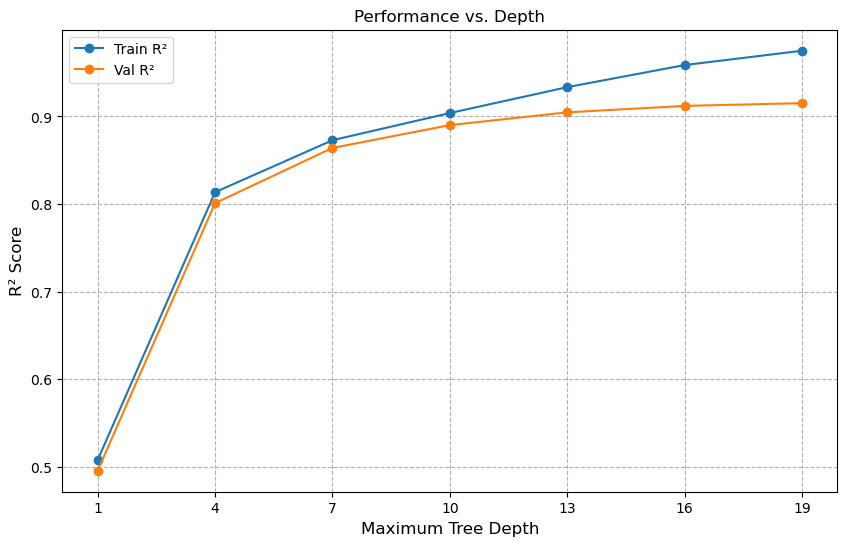

In [148]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [149]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [150]:
rf_one_v3 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_one_v3

,r2,MAPE,MdAPE,MAE
Train Set,0.968187,5.943282,4.513941,$67485.43
Validation Set,0.883385,10.617072,7.499560,$124341.21
Test Set,0.898906,10.078233,7.076833,$120850.4


Model performance for the smaller training window is still on par with the full baseline, so we can conclude that the model is not overfitting to any specific moment in time.

### Model Two: Tuning `max_features`

Random forests have many hyperparameters that we can tune. One of those hyperparameters is `max_features`, which decides how many features each decision tree in the forest can use. High max features (the default value of `1`) may be more accurate, but can lead to overfitting. Choosing low max features (`sqrt` or `log2`) reduces overfitting, but might accidentally lead to underfitting. The above models used `1` for `max_features`, so let's test `sqrt` and `log2`.

In [151]:
x_train = training[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_train = training["ClosePriceLog"]

x_val = validation[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols].drop(columns = ["PropertyMonth", "ClosePriceLog"])
y_test = testing["ClosePriceLog"]

In [152]:
# The previous model worked very well. It is a good idea now to tune that one further
# Above model used max_features = 1.0 (all features). Try different options for max_features

#max_features = "sqrt"
rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, max_features = "sqrt")
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

In [153]:
rf_two_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_two_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.954851,6.831652,5.157664,$79000.74
Validation Set,0.876935,10.755635,7.783662,$127217.64
Test Set,0.893651,10.150285,7.419401,$123538.83


In [154]:
# max_features = "log2"
rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, max_features = "log2")
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

In [155]:
rf_two_v2 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_two_v2

,r2,MAPE,MdAPE,MAE
Train Set,0.954851,6.831652,5.157664,$79000.74
Validation Set,0.876935,10.755635,7.783662,$127217.64
Test Set,0.893651,10.150285,7.419401,$123538.83


As expected, changing the value of `max_features` to a smaller number decreases model accuracy. Since there is no evidence of our previous model overfitting, it is likely not necessary to change `max_features` from the default.

### Model Three: Tuning `min_samples_split`

Another hyperparamter that we can tune is `min_samples_split`, which determines how many samples must be present in an internal node before it can be split. The default value is `2`. Smaller values can lead to overfitting, but higher values might lead to underfitting. Let's test a range of values in this section.

In [156]:
splits = range(2, 11)
train_r2_scores = {}
val_r2_scores = {}

for split in splits:
    rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, min_samples_split=split)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[split] = train_r2
    val_r2_scores[split] = val_r2

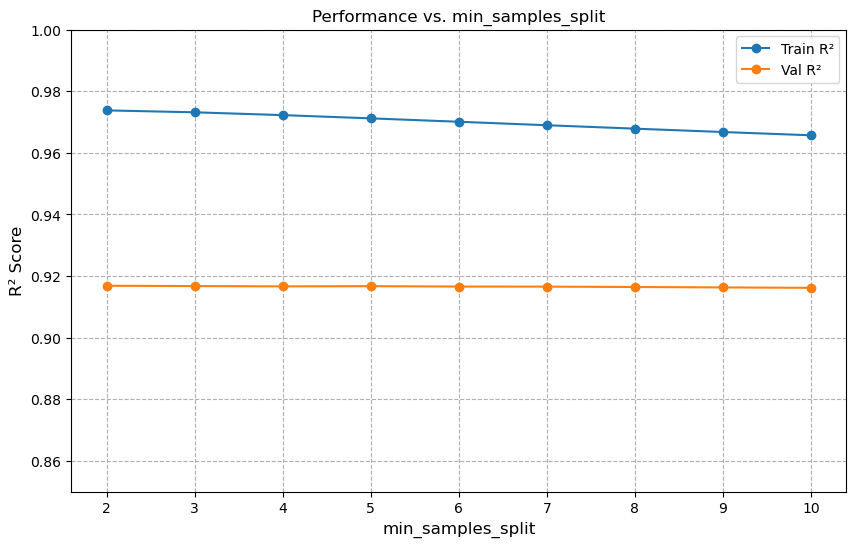

In [157]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("min_samples_split", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. min_samples_split")
plt.xticks(splits)
plt.ylim(0.85, 1) 
plt.grid(True, linestyle="--")
plt.legend()

In [158]:
best_split = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Split: {best_split}")

rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, min_samples_split=best_split)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Split: 2


In [159]:
rf_three_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_three_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.966687,6.124628,4.647852,$69358.02
Validation Set,0.886422,10.533720,7.483323,$122930.56
Test Set,0.902822,9.853777,6.941994,$118341.45


Here, we get the same values as the baseline because the default value of `2` remains the best option.

### Model Four: Tuning `min_samples_leaf`

One more hyperparameter that we can tune is `min_samples_leaf`. This hyperparamter is similar to `min_samples_split`, but instead determines the minimum amount of samples that are required to create a leaf node. The default value is `1`. Once again, low values can cause overfitting, but high values might cause underfitting. Let's test a range of options for `min_samples_leaf` here.

In [160]:
leaves = range(1, 11)
train_r2_scores = {}
val_r2_scores = {}

for leaf in leaves:
    rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, min_samples_leaf = leaf)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[leaf] = train_r2
    val_r2_scores[leaf] = val_r2

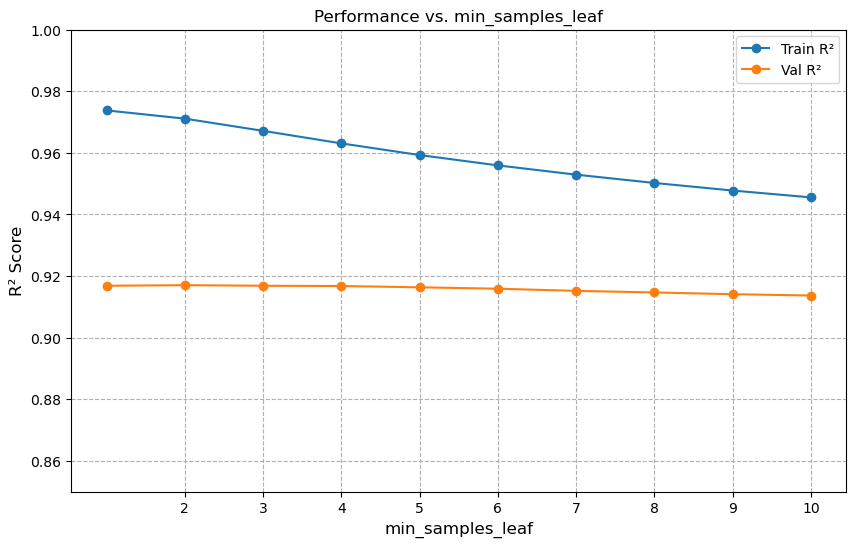

In [161]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("min_samples_leaf", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. min_samples_leaf")
plt.xticks(splits)
plt.ylim(0.85, 1) 
plt.grid(True, linestyle="--")
plt.legend()

In [162]:
best_leaf = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Leaf: {best_leaf}")

rf = RandomForestRegressor(n_estimators=100, max_depth=19, random_state=42, n_jobs=-1, min_samples_leaf = best_leaf)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Leaf: 2


In [163]:
rf_four_v1 = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_four_v1

,r2,MAPE,MdAPE,MAE
Train Set,0.962798,6.223967,4.562807,$70663.42
Validation Set,0.886339,10.502084,7.436951,$122714.68
Test Set,0.902892,9.835547,6.860274,$118046.21


Unlike the other sections, a value other than the default was the highest performing option. These results indicate that a `max_samples_leaf` of `2` (rather than the default `1`) might be the best option for our dataset.

### Model Five: BedBathRatio and PropertyAge

Two features, BedBathRatio and PropertyAge, were created during the feature engineering done in week six. Test how model performance changes with the inclusion of these new features.

In [196]:
# Read in the training and test sets created in week six

train_and_val = pd.read_csv("feat_eng_train.csv")
testing = pd.read_csv("feat_eng_test.csv")

In [197]:
training = train_and_val[~(train_and_val["PropertyMonth"] == "2026-03-01")]
validation = train_and_val[train_and_val["PropertyMonth"] == "2026-03-01"]

print(train_and_val.shape, training.shape, validation.shape)

(265296, 153) (255004, 153) (10292, 153)


In [166]:
common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "BedBathRatio", "PropertyAge"]

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [167]:
depths = range(1, 20, 3)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

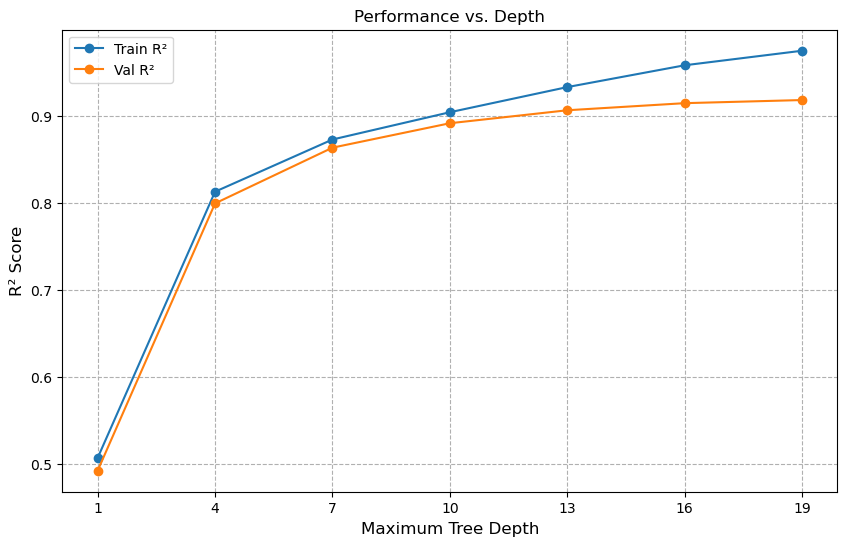

In [168]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [170]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [171]:
rf_five = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_five

,r2,MAPE,MdAPE,MAE
Train Set,0.967704,6.044371,4.576884,$68430.18
Validation Set,0.887568,10.443620,7.395926,$122056.82
Test Set,0.904624,9.739986,6.814117,$116968.44


Interestingly, the addition of these features did not improve the decision tree, but they do improve the random forest. This is likely because random forests are designed to handle more complex features. For more complex models like decision trees, it seems worth it to keep these feature engineered additions.

### Model Six: Improved School Districts

During week six, the existing dataset was joined with the California School District Areas 2024-2025 dataset (https://data.ca.gov/@california-department-of-education/california-school-district-areas-2024-25) to improve the locational data. Test how the model performance changes with these new features. Additionally, since BedBathRatio and PropertyAge did increase model performance, we will continue to use them as features in this section.

In [208]:
common_cols = ["ViewYN", "PoolPrivateYN", "AttachedGarageYN", "FireplaceYN", "NewConstructionYN",
            "Longitude", "Latitude", 
            "LivingAreaLog", "AssociationFeeLog", "LotSizeSquareFeetLog" ,
            "ParkingTotal", "GarageSpaces", "BathroomsTotalInteger", "BedroomsTotal", "MainLevelBedrooms", "Stories",
            "Bamboo", "Brick", "Carpet", "Concrete", "Laminate", "SeeRemarks", "Stone", "Tile", "Unknown", "Vinyl", "Wood",
            "ListOfficeName_enc", "CountyOrParish_enc", "HighSchoolDistrict_enc", "City_enc", "PostalCode_enc", "YearBuilt_enc",
            "DistrictName_elem_enc", "DistrictName_unif_enc", "DistrictName_high_enc",
            "BedBathRatio", "PropertyAge",
            'EnrollTotal_high', 'EnrollCharter_high', 'EnrollNonCharter_high', 'AApct_high', 'AAcount_high', 'AIpct_high',
            'AIcount_high', 'ASpct_high', 'AScount_high', 'FIpct_high', 'FIcount_high', 'HIpct_high', 'HIcount_high', 'PIpct_high',
            'PIcount_high', 'WHpct_high', 'WHcount_high', 'MRpct_high', 'MRcount_high', 'NRpct_high', 'NRcount_high', 'ELpct_high',
            'ELcount_high', 'FOSpct_high', 'FOScount_high','HOMpct_high','HOMcount_high','MIGpct_high','MIGcount_high','SWDpct_high',
            'SWDcount_high','SEDpct_high','SEDcount_high', 'EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem','AApct_elem',
            'AAcount_elem','AIpct_elem','AIcount_elem','ASpct_elem','AScount_elem','FIpct_elem','FIcount_elem','HIpct_elem','HIcount_elem',
            'PIpct_elem','PIcount_elem','WHpct_elem','WHcount_elem','MRpct_elem','MRcount_elem','NRpct_elem','NRcount_elem','ELpct_elem',
            'ELcount_elem','FOSpct_elem','FOScount_elem','HOMpct_elem','HOMcount_elem','MIGpct_elem','MIGcount_elem','SWDpct_elem',
            'SWDcount_elem','SEDpct_elem','SEDcount_elem','EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif','AApct_unif',
            'AAcount_unif','AIpct_unif','AIcount_unif','ASpct_unif','AScount_unif','FIpct_unif','FIcount_unif','HIpct_unif','HIcount_unif',
            'PIpct_unif','PIcount_unif','WHpct_unif','WHcount_unif','MRpct_unif','MRcount_unif','NRpct_unif','NRcount_unif','ELpct_unif',
            'ELcount_unif','FOSpct_unif','FOScount_unif','HOMpct_unif','HOMcount_unif','MIGpct_unif','MIGcount_unif','SWDpct_unif',
            'SWDcount_unif','SEDpct_unif','SEDcount_unif']

x_train = training[common_cols]
y_train = training["ClosePriceLog"]

x_val = validation[common_cols]  
y_val = validation["ClosePriceLog"]

x_test = testing[common_cols]
y_test = testing["ClosePriceLog"]

In [209]:
depths = range(1, 20, 3)

train_r2_scores = {}
val_r2_scores = {}

for depth in depths:
    rf = RandomForestRegressor(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf.fit(x_train, y_train)

    train_r2 = rf.score(x_train, y_train)
    val_r2 = rf.score(x_val, y_val)

    train_r2_scores[depth] = train_r2
    val_r2_scores[depth] = val_r2

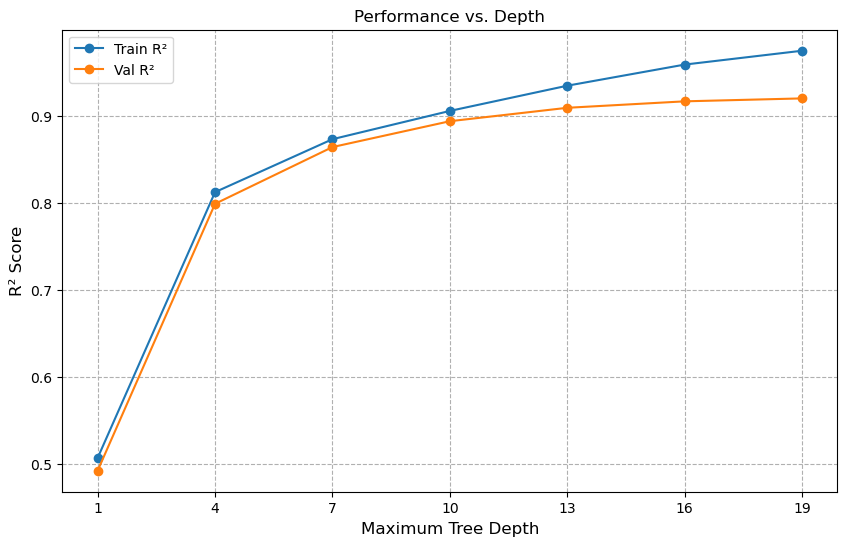

In [210]:
plt.figure(figsize=(10, 6))
plt.plot(train_r2_scores.keys(), list(train_r2_scores.values()), marker="o", label="Train R²")
plt.plot(val_r2_scores.keys(), list(val_r2_scores.values()), marker="o", label="Val R²")

plt.xlabel("Maximum Tree Depth", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.title("Performance vs. Depth")
plt.xticks(depths)
plt.grid(True, linestyle="--")
plt.legend()

In [211]:
best_depth = max(val_r2_scores, key=val_r2_scores.get)
print(f"Best Depth: {best_depth}")

rf = RandomForestRegressor(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_train = rf.predict(x_train)
pred_val = rf.predict(x_val)
pred_test = rf.predict(x_test)

r2_train, mape_train, mdape_train, mae_train = metrics(y_train, pred_train)
r2_val, mape_val, mdape_val, mae_val = metrics(y_val, pred_val)
r2_test, mape_test, mdape_test, mae_test = metrics(y_test, pred_test)

Best Depth: 19


In [212]:
rf_six = metric_df(r2_train, mape_train, mdape_train, mae_train, 
                        r2_val, mape_val, mdape_val, mae_val,
                        r2_test, mape_test, mdape_test, mae_test)
rf_six

,r2,MAPE,MdAPE,MAE
Train Set,0.968519,5.962531,4.518710,$67465.35
Validation Set,0.890590,10.267801,7.313927,$120166.53
Test Set,0.905958,9.683137,6.796715,$116191.37


This is the best random forest model so far. The inclusion of more features has repeatedly lead to higher performane for the random forests models (as opposed to the decision trees). We can conclude that random forests are certainly better for modeling this complex dataset.

### Random Forest Summary

| Model | Test r2 | Test MAPE | Test MdAPE | Test MAE |
| ----- | ------- | --------- | ---------- | -------- |
| Model One (Baseline) | 0.902822 | 9.853777| 6.941994| \$118,341|
| Model Two (Tuning Max Features) | 0.893651 | 10.150285 | 7.419401 | \$123,538|
| Model Three (Tuning Min Samples Split) | 0.902822 | 9.853777 | 6.941994| \$118,341|
| Model Four (Tuning Min Samples Leaf) | 0.902892| 9.853777 |  6.860274 |  \$118,046|
| Model Five (Feature Engineering Additions) | 0.904624| 9.739986| 6.814117 | \$116,968 |
| **Model Six (Improved School Districts)** | **0.905958** | **9.683137** | **6.796715** | **\$116,191** |

As expected, random forests outperform the linear regression models and decision trees on the same data. Achieving an $R^2$ score above 0.9 and MAPE/MdAPE below 10% indicate that our model performs very well. However, we can push this even further by testing more advanced models, such as adding gradient boosting our tree models.